# Tiempo de vuelo de muones

Kernel: `C:\Dev\Fisica\.venv`. Correr todo una vez (*Run All*) y después:

1. **Visor** (sección 2): elegir corrida y filtro, recorrer con ◀ ▶ o elegir el evento en la lista.
   La casilla **usar** lo suma o lo saca de la distribución. Las marcas se guardan solas en `seleccion_tof.csv`.
2. **Distribución** (sección 3): volver a correr esa celda para recalcular con la selección actual.

$\Delta t_{31} = t_{\rm CFD}(\mathrm{CH3}) - t_{\rm CFD}(\mathrm{CH1})$, con $d_{13} = (61{,}2 \pm 1{,}4)$ cm entre CH1 (arriba)
y CH3 (abajo). Tiempo de vuelo $= \Delta t_{31} - $ `OFFSET_NS` y $\beta = d_{13} / (c \cdot \mathrm{TOF})$.

In [11]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

DIR_TOF = Path('../grupo_7_jueves/medidas/tof')
ARCHIVO_SELECCION = Path('seleccion_tof.csv')   # marcas hechas a mano en el visor

C_M_NS = 0.299792458        # velocidad de la luz [m/ns]
D13, SD13 = 0.612, 0.014    # separación CH1-CH3 [m]
TOF_C = D13 / C_M_NS        # tiempo de vuelo a beta = 1 [ns]
OFFSET_NS = 0.0             # offset de dt31 (cables, PMTs, electrónica) [ns]. Todavía no medido.

CANALES = (1, 2, 3)
NOMBRE_CANAL = {1: 'CH1 (arriba)', 2: 'CH2 (medio)', 3: 'CH3 (abajo)'}
COLOR_CANAL = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 11, 'legend.frameon': False,
    'axes.grid': True, 'grid.color': '#e4e3dd', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
})

## 1. Datos y clasificación automática

- **ráfaga**: 3 o más eventos de la misma corrida a menos de 30 s (interferencia; los muones llegan a ~10 por hora).
- **saturado**: algún canal con amplitud ≥ 480 mV.
- **incompleto**: algún canal sin tiempo CFD.
- **candidato**: el resto.

Por defecto (`criterio_auto`) se usan los candidatos con $-10 < \Delta t_{31} < 15$ ns: los pocos candidatos con
$|\Delta t_{31}|$ de 20 a 90 ns tienen 250–480 mV en los tres canales (los muones dan 100–200 mV) y parecen la
misma interferencia. Las marcas del visor mandan sobre el criterio automático.

In [12]:
def leer_run_id(ruta):
    with open(ruta, encoding='utf-8', errors='replace') as f:
        for linea in f:
            if not linea.startswith('#'):
                break
            m = re.match(r'#\s*run_id\s*:\s*(\S+)', linea)
            if m:
                return m.group(1)
    return ruta.stem


def clasificar(ev, ventana_s=30, vecinos_min=3, amp_sat=480):
    cat = np.full(len(ev), 'candidato', dtype=object)
    cat[(ev[[f'A{ch}' for ch in CANALES]] >= amp_sat).any(axis=1).to_numpy()] = 'saturado'
    for _, g in ev.groupby('run'):
        t = (g['ts'] - g['ts'].min()).dt.total_seconds().to_numpy()
        orden = np.argsort(t)
        ts = t[orden]
        n = np.searchsorted(ts, ts + ventana_s, 'right') - np.searchsorted(ts, ts - ventana_s, 'left') - 1
        rafaga = np.empty(len(t), bool)
        rafaga[orden] = n >= vecinos_min
        cat[g.index.to_numpy()[rafaga]] = 'ráfaga'
    cat[ev[[f't_cfd{ch}_ns' for ch in CANALES]].isna().any(axis=1).to_numpy()] = 'incompleto'
    return cat


tablas = []
for ruta in sorted(DIR_TOF.glob('*_eventos.csv')):
    df = pd.read_csv(ruta, comment='#', on_bad_lines='skip')
    df['run'] = leer_run_id(ruta)
    tablas.append(df)
ev = pd.concat(tablas, ignore_index=True)
ev['ts'] = pd.to_datetime(ev['timestamp'], format='%Y-%m-%d %H:%M:%S.%f')
for ch in CANALES:
    ev[f'A{ch}'] = -ev[f'amp{ch}_mV']           # amplitud positiva [mV]
ev['cat'] = clasificar(ev)
ev = ev.set_index(['run', 'evento']).sort_index()
RUNS = ev.index.unique('run').tolist()

display(pd.crosstab(ev.index.get_level_values('run'), ev['cat'], rownames=['corrida'], colnames=['categoría'],
                    margins=True, margins_name='total'))

categoría,candidato,incompleto,ráfaga,saturado,total
corrida,,,,,
tof_d61.2cm_20261029_180950,19,1,5278,7,5305
tof_d61.2cm_20261029_194928,107,2,4,14,127
total,126,3,5282,21,5432


In [13]:
def criterio_auto(ev):
    # Qué eventos se usan si no se marcaron a mano. Editar y volver a correr desde acá.
    return (ev['cat'] == 'candidato') & ev['dt31_ns'].between(-10, 15)


def leer_marcas():
    if not ARCHIVO_SELECCION.exists():
        return {}
    m = pd.read_csv(ARCHIVO_SELECCION)
    return {(r, int(e)): bool(u) for r, e, u in m[['run', 'evento', 'usar']].itertuples(index=False)}


def marcar(run, evento, usar):
    clave = (run, int(evento))
    if usar == ev.at[clave, 'auto']:
        MARCAS.pop(clave, None)          # coincide con el criterio automático: no hace falta marca
    else:
        MARCAS[clave] = usar
    ev.at[clave, 'usar'] = usar
    pd.DataFrame([(r, e, u) for (r, e), u in sorted(MARCAS.items())],
                 columns=['run', 'evento', 'usar']).to_csv(ARCHIVO_SELECCION, index=False)


MARCAS = leer_marcas()
ev['auto'] = criterio_auto(ev)
ev['usar'] = ev['auto']
for clave, usar in MARCAS.items():
    if clave in ev.index:
        ev.at[clave, 'usar'] = usar
print(f"{ev['usar'].sum()} eventos usados: {ev['auto'].sum()} por el criterio automático, "
      f"{len(MARCAS)} cambios a mano en {ARCHIVO_SELECCION}")

115 eventos usados: 115 por el criterio automático, 0 cambios a mano en seleccion_tof.csv


In [14]:
# Formas de onda: se indexa cada *_ondas.txt una vez (posición de cada 'Event #N') y se lee solo el evento pedido.
RE_EVENTO = re.compile(rb'^Event #(\d+)[^\n]*\n', re.M)
_INDICE = {}


def leer_onda(run, evento):
    if run not in _INDICE:
        _INDICE[run] = {}
        for ruta in sorted(DIR_TOF.glob(f'{run}_idx*_ondas.txt')):
            datos = ruta.read_bytes()
            ms = list(RE_EVENTO.finditer(datos))
            for k, m in enumerate(ms):
                fin = ms[k + 1].start() if k + 1 < len(ms) else len(datos)
                _INDICE[run][int(m.group(1))] = (ruta, m.end(), fin)
    if evento not in _INDICE[run]:
        return None
    ruta, ini, fin = _INDICE[run][evento]
    with open(ruta, 'rb') as f:
        f.seek(ini)
        arr = np.array(f.read(fin - ini).split(), dtype=float).reshape(-1, 2 * len(CANALES))
    return {ch: (arr[:, 2 * k], arr[:, 2 * k + 1]) for k, ch in enumerate(CANALES)}

## 2. Visor

A la izquierda las formas de onda del evento (líneas cortadas: $t_{\rm CFD}$; punteada: umbral de −100 mV).
A la derecha el $\Delta t_{31}$ de todos los eventos que se están usando, con el evento actual marcado: se actualiza
al tildar o destildar **usar**.

In [ ]:
def dibujar_onda(ax, run, e):
    f = ev.loc[(run, e)]
    ondas = leer_onda(run, e)
    if ondas is None:
        ax.text(0.5, 0.5, 'sin forma de onda', transform=ax.transAxes, ha='center')
        return
    for ch in CANALES:
        t, u = ondas[ch]
        ax.plot(t, u, ".", color=COLOR_CANAL[ch], lw=1.3, label=NOMBRE_CANAL[ch])
        if np.isfinite(f[f't_cfd{ch}_ns']):
            ax.axvline(f[f't_cfd{ch}_ns'], color=COLOR_CANAL[ch], lw=1, ls='--')
    ax.axhline(-100, color='#8a8984', lw=1, ls=':')
    ax.axhline(-120, color='red', lw=1, ls=':')

    tcs = [f[f't_cfd{ch}_ns'] for ch in CANALES if np.isfinite(f[f't_cfd{ch}_ns'])]
    ax.set_xlim((min(tcs) - 15, max(tcs) + 30) if tcs else (0, 200))
    ax.set_xlabel('t [ns]')
    ax.set_ylabel('V [mV]')
    ax.legend(loc='lower right', fontsize=9)


def dibujar_hist_usados(ax, dt_actual=np.nan):
    x = ev.loc[ev['usar'], 'dt31_ns'].dropna()
    bins = np.arange(-10, 15.01, 0.5)
    ax.hist(x, bins=bins, color='#2a78d6', edgecolor='white', lw=0.6)
    ax.axvline(OFFSET_NS + TOF_C, color='#8a8984', lw=1.2, ls='--', label=r'$\beta = 1$')
    if np.isfinite(dt_actual):
        ax.axvline(dt_actual, color='#1c1c1a', lw=1.6, label='este evento')
    fuera = ((x < bins[0]) | (x > bins[-1])).sum()
    ax.set_title(f'usados: N = {len(x)}' + (f' ({fuera} fuera del gráfico)' if fuera else ''), fontsize=10)
    ax.set_xlabel(r'$\Delta t_{31}$ [ns]')
    ax.set_ylabel('eventos / 0,5 ns')
    ax.legend(loc='upper left', fontsize=9)


FILTROS = ['usados', 'no usados', 'todos', 'candidato', 'ráfaga', 'saturado', 'incompleto']
w_run = widgets.Dropdown(description='Corrida', layout=widgets.Layout(width='430px'),
                         options=[(f'{r}  ({len(ev.loc[r])} ev)', r) for r in RUNS], value=RUNS[-1])
w_filtro = widgets.Dropdown(options=FILTROS, value='usados', description='Mostrar')
w_ev = widgets.Dropdown(description='Evento', layout=widgets.Layout(width='200px'))
b_ant = widgets.Button(description='◀', layout=widgets.Layout(width='45px'))
b_sig = widgets.Button(description='▶', layout=widgets.Layout(width='45px'))
w_usar = widgets.Checkbox(description='usar en la distribución', indent=False)
w_info = widgets.HTML()
salida = widgets.Output()
_quieto = [False]      # True mientras el código cambia widgets (para no disparar callbacks)


def eventos_filtrados():
    s = ev.loc[w_run.value]
    f = w_filtro.value
    if f == 'usados':
        s = s[s['usar']]
    elif f == 'no usados':
        s = s[~s['usar']]
    elif f != 'todos':
        s = s[s['cat'] == f]
    return s.index.tolist()


def cambiar_lista(*_):
    eventos = eventos_filtrados()             # la lista queda fija hasta cambiar corrida o filtro
    _quieto[0] = True
    w_ev.options = eventos
    w_ev.value = eventos[0] if eventos else None
    _quieto[0] = False
    dibujar()


def mover(paso):
    lista = list(w_ev.options)
    if lista:
        i = lista.index(w_ev.value) + paso if w_ev.value in lista else 0
        w_ev.value = lista[min(max(i, 0), len(lista) - 1)]


def al_tildar(cambio):
    if not _quieto[0] and w_ev.value is not None:
        marcar(w_run.value, w_ev.value, cambio['new'])
        dibujar()


def dibujar(*_):
    if _quieto[0]:
        return
    run, e = w_run.value, w_ev.value
    with salida:
        salida.clear_output(wait=True)
        if e is None:
            w_info.value = 'No hay eventos con ese filtro.'
            return
        f = ev.loc[(run, e)]
        _quieto[0] = True
        w_usar.value = bool(f['usar'])
        _quieto[0] = False
        lista = list(w_ev.options)
        w_info.value = (f"<b>evento {e}</b> ({lista.index(e) + 1} de {len(lista)}) · {f['timestamp']} · "
                        f"<b>{f['cat']}</b> · A1, A2, A3 = {f['A1']:.0f}, {f['A2']:.0f}, {f['A3']:.0f} mV · "
                        f"Δt31 = {f['dt31_ns']:.2f} ns · Δt21 = {f['dt21_ns']:.2f} ns")
        fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.5, 1]))
        dibujar_onda(a, run, e)
        dibujar_hist_usados(b, f['dt31_ns'])
        fig.tight_layout()
        plt.show()


w_run.observe(cambiar_lista, 'value')
w_filtro.observe(cambiar_lista, 'value')
w_ev.observe(dibujar, 'value')
w_usar.observe(al_tildar, 'value')
b_ant.on_click(lambda _: mover(-1))
b_sig.on_click(lambda _: mover(+1))

display(widgets.VBox([widgets.HBox([w_run, w_filtro]), widgets.HBox([b_ant, w_ev, b_sig, w_usar]), w_info, salida]))
cambiar_lista()

## 3. Distribución de velocidades

Con los eventos marcados como **usar**. Volver a correr después de cambiar la selección o `OFFSET_NS`.

Ojo: la resolución en $\Delta t_{31}$ (~2 ns) es del orden del tiempo de vuelo mismo (2,04 ns a $\beta = 1$), así que
$\beta$ evento por evento es muy ancha y los eventos con TOF ≤ 0 no dan velocidad. El valor que vale es $\beta$
calculado con el TOF medio.

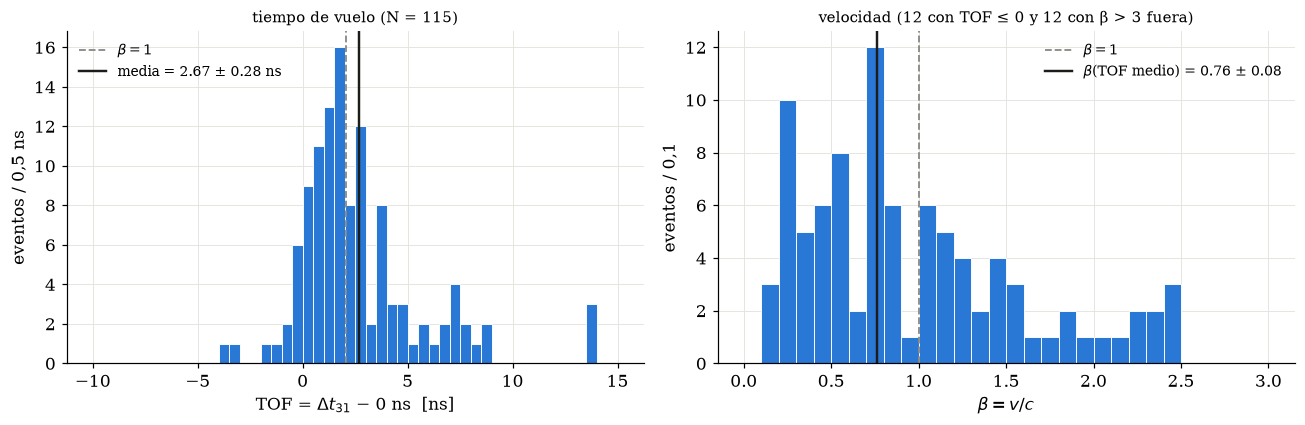

N                       115.000
TOF medio [ns]            2.672
err TOF [ns]              0.281
σ TOF [ns]                3.012
TOF mediana [ns]          1.899
β (TOF medio)             0.764
err β                     0.082
v (TOF medio) [m/ns]      0.229
β (TOF mediana)           1.075
dtype: float64

In [16]:
def distribucion(offset=OFFSET_NS):
    u = ev[ev['usar']].dropna(subset=['dt31_ns'])
    tof = u['dt31_ns'] - offset
    beta = D13 / (C_M_NS * tof.where(tof > 0))
    n, m = len(tof), tof.mean()
    em = tof.std(ddof=1) / np.sqrt(n)
    b_m = D13 / (C_M_NS * m)
    eb = b_m * np.hypot(SD13 / D13, em / m)

    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    a.hist(tof, bins=np.arange(-10, 15.01, 0.5), color='#2a78d6', edgecolor='white', lw=0.6)
    a.axvline(TOF_C, color='#8a8984', lw=1.2, ls='--', label=r'$\beta = 1$')
    a.axvline(m, color='#1c1c1a', lw=1.6, label=f'media = {m:.2f} ± {em:.2f} ns')
    a.set_xlabel(f'TOF = $\\Delta t_{{31}}$ − {offset:g} ns  [ns]')
    a.set_ylabel('eventos / 0,5 ns')
    a.set_title(f'tiempo de vuelo (N = {n})', fontsize=10)
    a.legend(loc='upper left', fontsize=9)

    bins_b = np.arange(0, 3.01, 0.1)
    b.hist(beta.dropna(), bins=bins_b, color='#2a78d6', edgecolor='white', lw=0.6)
    b.axvline(1, color='#8a8984', lw=1.2, ls='--', label=r'$\beta = 1$')
    b.axvline(b_m, color='#1c1c1a', lw=1.6, label=rf'$\beta$(TOF medio) = {b_m:.2f} ± {eb:.2f}')
    b.set_xlabel(r'$\beta = v/c$')
    b.set_ylabel('eventos / 0,1')
    b.set_title(f'velocidad ({(tof <= 0).sum()} con TOF ≤ 0 y {(beta > bins_b[-1]).sum()} con β > 3 fuera)',
                fontsize=10)
    b.legend(loc='upper right', fontsize=9)
    fig.tight_layout()
    plt.show()

    return pd.Series({'N': n, 'TOF medio [ns]': m, 'err TOF [ns]': em, 'σ TOF [ns]': tof.std(ddof=1),
                      'TOF mediana [ns]': tof.median(), 'β (TOF medio)': b_m, 'err β': eb,
                      'v (TOF medio) [m/ns]': b_m * C_M_NS, 'β (TOF mediana)': D13 / (C_M_NS * tof.median())}).round(3)


distribucion()